# MARL Environment Profiling

이 노트북은 MARL 환경을 3차원 공간으로 프로파일링합니다.

## 세 가지 축:
1. **Agent Scale**: $\log_{10}(N)$
2. **Alignment**: $\frac{1}{N} \sum_{i=1}^N \text{Corr}(r^i, \sum_{j \neq i} r^j)$ (Spearman correlation)
3. **Interdependency**: $\mathbb{E}_{s} [ \text{mean}_{i \neq j} ( \frac{\mathbb{E}_{\mathbf{a}^{-i}} [\text{Var}_{a^i}(Q_j | \mathbf{a}^{-i})]}{\text{Var}_{\mathbf{a}}(Q_j)} ) ]$ (under heuristic policy)

## Heuristic Policy:
Random policy 대신 **heuristic policy**를 사용하여 프로파일링합니다. 
- Stag-Hunt 환경의 경우: 에이전트가 가장 가까운 객체(Stag 또는 Hare) 방향으로 이동할 확률을 높임 (default 90%)
- 이를 통해 에이전트가 "상호작용이 발생할 법한 영역"에 머물도록 하여 bias와 variance를 줄입니다.


In [43]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from scipy.stats import spearmanr
import math
import sys
import os

# 프로젝트 루트를 sys.path에 추가
# 현재 디렉토리에서 시작해서 envs 디렉토리를 찾을 때까지 상위로 이동
_current_dir = os.path.abspath(os.getcwd())
_project_root = _current_dir

# envs 디렉토리를 찾을 때까지 상위 디렉토리로 이동
while _project_root != os.path.dirname(_project_root):  # 루트 디렉토리에 도달할 때까지
    if os.path.exists(os.path.join(_project_root, 'envs')):
        break
    _project_root = os.path.dirname(_project_root)

if _project_root not in sys.path:
    sys.path.insert(0, _project_root)

from envs.multi_agent_env import StagHuntEnv, LBForagingWrapper


## MARLProfiler 클래스 정의


In [ ]:
import numpy as np
import math
import copy
from scipy.stats import spearmanr
from joblib import Parallel, delayed
import matplotlib.pyplot as plt
from contextlib import contextmanager
import sys
import os

@contextmanager
def suppress_stdout():
    """출력을 억제하는 context manager"""
    with open(os.devnull, 'w') as devnull:
        old_stdout = sys.stdout
        sys.stdout = devnull
        try:
            yield
        finally:
            sys.stdout = old_stdout

class MARLProfiler:
    def __init__(self, env_fn, env_kwargs, gamma=0.99):
        """
        Args:
            env_fn: 환경을 생성하는 함수 (예: StagHuntEnv)
            env_kwargs: 환경 생성에 필요한 인자들
        """
        self.env_fn = env_fn
        self.env_kwargs = env_kwargs
        self.gamma = gamma
        
        # 임시 환경 생성하여 정보 추출 (출력 억제)
        with suppress_stdout():
            temp_env = self.env_fn(**self.env_kwargs)
        self.n_agents = temp_env.num_agents
        self.action_dim = temp_env.get_action_dim() if hasattr(temp_env, 'get_action_dim') else temp_env.action_dim
        self.max_steps = getattr(temp_env, 'max_steps', 50)
        del temp_env
        
    def calculate_axis1(self): # log_10(\mathcal{A}^N)
        return self.n_agents*math.log10(self.action_dim) 

    def calculate_axis2_and_3(self, num_states=50, num_samples=20, num_rollouts=10, n_jobs=-1):
        """
        통합 프로파일링 함수:
        - Axis 2: Single-path Return (G) 기반 상관관계 (이전 방식 복구)
        - Axis 3: Expected Variance 기반 결합 밀도 (수학적 안정성 유지)
        """
        def process_single_state(state_idx):
            local_env = self._make_env()
            state_seed = 70000 + state_idx * 1000
            state_rng = np.random.RandomState(state_seed)
            local_env.reset()
            state_info = self._capture_state_info(local_env)

            # --- [Step 1] 데이터 수집 (Axis 2용 G & Axis 3 분모용 Q) ---
            all_return_samples = []  # Axis 2용 (Single-path G)
            q_samples_for_total_var = []  # Axis 3 분모용 (Stable Q)

            for p in range(num_samples):
                joint_action = {k: self._sample_heuristic_action(local_env, k, state_rng) for k in range(self.n_agents)}
                
                # Axis 2용: 단일 경로 시뮬레이션 결과 (G) 수집
                _, ret_g = self._get_step_and_return(local_env, state_info, joint_action, 
                                                     state_seed + p, horizon=50)
                all_return_samples.append(ret_g)
                
                # Axis 3용: 평균 리턴 (Q) 수집
                q_val = self._get_stable_q(local_env, state_info, joint_action, 
                                           state_seed + p, num_rollouts, horizon=50)
                q_samples_for_total_var.append(q_val)
            
            all_return_samples = np.array(all_return_samples) # [num_samples, n_agents]
            q_samples_for_total_var = np.array(q_samples_for_total_var) # [num_samples, n_agents]

            # --- [Step 2] Axis 2: Strategic Alignment (Return G 기반) ---
            state_alignments = []
            total_ret_sum = all_return_samples.sum(axis=1, keepdims=True)
            others_ret_sum = total_ret_sum - all_return_samples
            
            for i in range(self.n_agents):
                gi, go = all_return_samples[:, i], others_ret_sum[:, i]
                # 상관계수 계산 (Spearman)
                corr = spearmanr(gi, go)[0] if np.std(gi) > 1e-6 and np.std(go) > 1e-6 else 0
                state_alignments.append(corr)
            axis2_val = np.mean(state_alignments)

            # --- [Step 3] Axis 3: Interdependency (Expected Variance 기반) ---
            total_vars_j = np.var(q_samples_for_total_var, axis=0) + 1e-9
            influence_matrix = np.zeros((self.n_agents, self.n_agents))
            
            # 외곽 기댓값(E)을 위한 샘플링 (계산 효율을 위해 일부 사용)
            num_outer_samples = min(10, num_samples)
            
            for i in range(self.n_agents):
                for j in range(self.n_agents):
                    if i == j: continue
                    
                    inner_variances = []
                    for _ in range(num_outer_samples):
                        fixed_others = {k: self._sample_heuristic_action(local_env, k, state_rng) for k in range(self.n_agents)}
                        
                        q_perturbed = []
                        for p in range(num_samples // 2):
                            test_actions = fixed_others.copy()
                            test_actions[i] = self._sample_heuristic_action(local_env, i, state_rng)
                            qv = self._get_stable_q(local_env, state_info, test_actions, state_seed + p*13, num_rollouts, 20)
                            q_perturbed.append(qv[j])
                        inner_variances.append(np.var(q_perturbed))
                    
                    # E[Var(Q_j | a_-i)] / Var(Q_j) 적용
                    influence_matrix[i, j] = np.mean(inner_variances) / total_vars_j[j] # * (num_agents - 1) # for correcting N-scale

            return axis2_val, influence_matrix

        # 병렬 처리 실행
        results = Parallel(n_jobs=n_jobs)(delayed(process_single_state)(s) for s in range(num_states))
        
        a2_vals = [r[0] for r in results]
        inf_matrices = [r[1] for r in results]
        
        avg_inf_matrix = np.mean(inf_matrices, axis=0)
        mask = ~np.eye(self.n_agents, dtype=bool)
        
        return (np.mean(a2_vals), np.std(a2_vals)), (avg_inf_matrix[mask].mean(), avg_inf_matrix[mask].std()), avg_inf_matrix
    
    def profile(self, num_states=100, num_samples=30, num_rollouts=10, n_jobs=-1):
        """통합 프로파일링 실행"""
        a1_val = self.calculate_axis1()
        (a2_mean, a2_std), (a3_mean, a3_std), _ = self.calculate_axis2_and_3(num_states, num_samples, num_rollouts, n_jobs)
        
        return {
            "Axis 1": (a1_val, 0),
            "Axis 2": (a2_mean, a2_std),
            "Axis 3": (a3_mean, a3_std)
        }

    # ------- Plot Functions ------- #
    def _draw_ellipsoid(self, ax, center, radii, color, alpha=0.2, wireframe=True, n_points=20):
        """
        3D 타원체를 그리는 헬퍼 함수 (축에 정렬된 타원체)
        
        Args:
            ax: 3D axes
            center: 타원체 중심 (x, y, z)
            radii: 각 축의 반지름 (rx, ry, rz) - X, Y, Z 축에 정렬
            color: 색상
            alpha: 투명도
            wireframe: True면 wireframe, False면 surface
            n_points: 타원체를 그리기 위한 점의 개수
        """
        u = np.linspace(0, 2 * np.pi, n_points)
        v = np.linspace(0, np.pi, n_points)
        
        # 축에 정렬된 타원체 파라미터화
        # X축 방향: radii[0], Y축 방향: radii[1], Z축 방향: radii[2]
        x = center[0] + radii[0] * np.outer(np.cos(u), np.sin(v))
        y = center[1] + radii[1] * np.outer(np.sin(u), np.sin(v))
        z = center[2] + radii[2] * np.outer(np.ones(np.size(u)), np.cos(v))
        
        if wireframe:
            ax.plot_wireframe(x, y, z, color=color, alpha=alpha, linewidth=0.5)
        else:
            ax.plot_surface(x, y, z, color=color, alpha=alpha, edgecolor='k')

    def plot_marl_space(self, results_dict, save_name="marl_profile.png", marker_dict=None):
        plt.style.use('seaborn-v0_8-white')
        fig, ax = plt.subplots(figsize=(10, 8))
       
        # X축: Reward Alignment, Y축: Interdependency
        ax.set_xlabel('Reward Alignment', fontsize=12, labelpad=10)
        ax.set_ylabel('Interdependency', fontsize=12, labelpad=10)
        ax.grid(True, linestyle='--', alpha=0.3)

        from matplotlib import colormaps
        import matplotlib.cm as cm
        from matplotlib.colors import LinearSegmentedColormap
        
        if marker_dict is None:
            marker_dict = {name: 'o' for name in results_dict.keys()}

        # Agent Scale 값의 범위를 계산 (colormap 정규화를 위해)
        a1_values = [res["Axis 1"][0] for res in results_dict.values()]  # mean 값들
        a1_min = min(a1_values)
        a1_max = max(a1_values)
        
        # Reds 컬러맵을 커스터마이즈하여 가장 작은 값도 더 진하게 보이도록 조정
        # 기존 Reds 컬러맵을 가져와서 하단 부분을 더 진한 색상으로 시작하도록 조정
        base_reds = colormaps['Reds']
        # Reds 컬러맵의 0.2~1.0 범위를 0.0~1.0으로 재매핑하여 더 진한 색상부터 시작
        colors = [base_reds(i) for i in np.linspace(0.2, 1.0, 256)]
        colormap = LinearSegmentedColormap.from_list('custom_reds', colors, N=256)
        
        norm = plt.Normalize(vmin=a1_min, vmax=a1_max)
        sm = cm.ScalarMappable(cmap=colormap, norm=norm)
        sm.set_array([])
        
        # 데이터 포인트 좌표를 순서대로 저장 (궤적을 그리기 위해)
        points = []
        
        for i, (name, res) in enumerate(results_dict.items()):
            # 결과 구조: (mean, std)
            a2_m, a2_s = res["Axis 2"]
            a3_m, a3_s = res["Axis 3"]
            a1_m, a1_s = res["Axis 1"]
            
            # Agent Scale 값에 따라 색상 결정 (진할수록 높은 값)
            color = colormap(norm(a1_m))
            marker = marker_dict.get(name, 'o')  # 기본값은 'o' (동그라미)

            # 포인트 좌표 저장 (2D)
            points.append((a2_m, a3_m, a1_m))

            # 1. 2D 타원 (Confidence Intervals) - X축과 Y축 방향의 std만 사용
            if a2_s > 0 or a3_s > 0:
                # X축과 Y축 방향의 반지름
                radius_x = max(a2_s, 0.01)
                radius_y = max(a3_s, 0.01)
                
                # 타원 그리기
                from matplotlib.patches import Ellipse
                ellipse = Ellipse((a2_m, a3_m), width=2*radius_x, height=2*radius_y,
                                 alpha=0.2, color=color, zorder=1)
                ax.add_patch(ellipse)
                
            # 2. 메인 포인트 (label 제거)
            ax.scatter(a2_m, a3_m, s=200, marker=marker, c=[a1_m], cmap=colormap, vmin=a1_min, vmax=a1_max,
                      alpha=0.9, edgecolors='k', linewidth=2, zorder=10)
            
        # Colorbar 추가 (Agent Scale 값 표시)
        cbar = plt.colorbar(sm, ax=ax, pad=0.02)
        cbar.set_label('Agent Scale', fontsize=11, rotation=270, labelpad=20)
        
        plt.title('MARL Problem Space (Agent Scale as Heatmap)\n', fontsize=15, fontweight='bold')
        plt.tight_layout()
        plt.savefig(save_name, dpi=300)
        plt.show()

    def plot_marl_space_3D(self, results_dict, save_name="marl_profile_3d.png", marker_dict=None):
        import matplotlib.pyplot as plt
        from mpl_toolkits.mplot3d import Axes3D
        from matplotlib.colors import LinearSegmentedColormap
        import matplotlib.cm as cm
        import numpy as np

        # marker_dict가 None이면 기본값으로 동그라미 설정
        if marker_dict is None:
            marker_dict = {name: 'o' for name in results_dict.keys()}

        # 1. 스타일 및 데이터 준비
        plt.style.use('seaborn-v0_8-white')
        fig = plt.figure(figsize=(12, 10))
        ax = fig.add_subplot(111, projection='3d')
        
        a1_vals = [res["Axis 1"][0] for res in results_dict.values()]
        a1_min, a1_max = min(a1_vals), max(a1_vals)
        # 바닥면의 높이를 데이터 최소값보다 약간 아래로 설정
        z_floor = max(0, a1_min - 0.2) if a1_min > 0.2 else 0

        # 2. 커스텀 Reds 컬러맵 (연한 색 제외)
        from matplotlib import colormaps
        base_reds = colormaps['Reds']
        colors = [base_reds(i) for i in np.linspace(0.3, 1.0, 256)]
        colormap = LinearSegmentedColormap.from_list('custom_reds', colors, N=256)
        norm = plt.Normalize(vmin=a1_min, vmax=a1_max)

        # 3. 데이터 루프
        for name, res in results_dict.items():
            a1_m, a1_s = res["Axis 1"]
            a2_m, a2_s = res["Axis 2"]
            a3_m, a3_s = res["Axis 3"]
            
            color = colormap(norm(a1_m))
            marker = marker_dict.get(name, 'o')  # 기본값은 'o' (동그라미)
            
            # (1) 바닥 평면에 투영된 타원 (Confidence Interval)
            if a2_s > 0 or a3_s > 0:
                theta = np.linspace(0, 2*np.pi, 100)
                # 1-std 범위를 타원으로 표현
                ellipse_x = a2_m + a2_s * np.cos(theta)
                ellipse_y = a3_m + a3_s * np.sin(theta)
                ax.plot(ellipse_x, ellipse_y, z_floor, color=color, alpha=0.3, linewidth=1)
                
                # 타원 내부 채우기 (Poly3DCollection 사용)
                from mpl_toolkits.mplot3d.art3d import Poly3DCollection
                # 타원의 좌표를 3D로 변환 (z는 모두 z_floor)
                ellipse_3d = list(zip(ellipse_x, ellipse_y, [z_floor] * len(ellipse_x)))
                poly = Poly3DCollection([ellipse_3d], alpha=0.05, facecolor=color, edgecolor='k')
                ax.add_collection3d(poly)

            # (2) 바닥 평면으로의 프로젝션 점선
            ax.plot([a2_m, a2_m], [a3_m, a3_m], [z_floor, a1_m], 
                    color='gray', linestyle='--', linewidth=1.0, alpha=1.0)

            # (2-1) 바닥 평면에 투영된 점에 x 표시 추가
            ax.scatter(a2_m, a3_m, z_floor, s=100, marker='x', color=color, 
                    linewidth=3.0, alpha=1.0, zorder=10)

            # (3) 실제 3D 데이터 포인트 (marker style 적용, label 제거)
            ax.scatter(a2_m, a3_m, a1_m, s=150, marker=marker, color=color, edgecolors='k', 
                    linewidth=1.5, alpha=0.9, depthshade=False)

        # 4. 축 및 뷰 설정
        ax.set_xlabel('\nAlignment', fontsize=11, labelpad=10)
        ax.set_ylabel('\nInterdependency', fontsize=11, labelpad=10)
        ax.set_zlabel('Agent Scale', fontsize=11, labelpad=10)
        
        # 축 범위 및 비율 설정
        ax.set_zlim(z_floor, a1_max + 0.2)
        ax.set_box_aspect((1, 1, 0.7)) # 높이 비율을 조절하여 차이 부각
        
        # 시점 조절: 바닥 평면이 잘 보이도록 설정
        ax.view_init(elev=25, azim=-60)

        # 5. 부가 요소
        sm = cm.ScalarMappable(cmap=colormap, norm=norm)
        sm.set_array([])
        cbar = fig.colorbar(sm, ax=ax, shrink=0.5, aspect=10, pad=0.1)
        cbar.set_label('Log Scale')
        
        plt.title('3D MARL Problem Space Profile\n', fontsize=16, fontweight='bold')
        plt.tight_layout()
        plt.savefig(save_name, dpi=300)
        plt.show()

    def plot_legend(self, results_dict, marker_dict=None, save_name="marl_profile_legend.png"):
        """
        별도의 figure로 legend를 생성하고 저장합니다.
        
        Args:
            results_dict: 프로파일링 결과 딕셔너리
            marker_dict: 마커 스타일 딕셔너리 (선택사항)
            save_name: 저장할 파일명
        """
        plt.style.use('seaborn-v0_8-white')
        fig, ax = plt.subplots(figsize=(8, 6))
        ax.axis('off')  # 축 숨기기
        
        if marker_dict is None:
            marker_dict = {name: 'o' for name in results_dict.keys()}
        
        # Agent Scale 값의 범위를 계산 (색상 일관성을 위해)
        a1_values = [res["Axis 1"][0] for res in results_dict.values()]
        a1_min = min(a1_values)
        a1_max = max(a1_values)
        
        from matplotlib import colormaps
        import matplotlib.cm as cm
        from matplotlib.colors import LinearSegmentedColormap
        
        base_reds = colormaps['Reds']
        colors = [base_reds(i) for i in np.linspace(0.2, 1.0, 256)]
        colormap = LinearSegmentedColormap.from_list('custom_reds', colors, N=256)
        norm = plt.Normalize(vmin=a1_min, vmax=a1_max)
        
        # Legend 항목 생성
        handles = []
        labels = []
        
        for name, res in results_dict.items():
            a1_m = res["Axis 1"][0]
            color = colormap(norm(a1_m))
            marker = marker_dict.get(name, 'o')
            
            # 마커와 색상을 사용하여 legend 항목 생성
            handle = ax.scatter([], [], s=200, marker=marker, color=color, 
                              edgecolors='k', linewidth=2, alpha=0.9, label=name)
            handles.append(handle)
            labels.append(name)
        
        # Legend 생성
        legend = ax.legend(handles, labels, loc='center', frameon=True, 
                          facecolor='white', framealpha=0.9, 
                          fontsize=10, ncol=1, columnspacing=1.0)
        
        plt.title('Legend', fontsize=14, fontweight='bold', pad=20)
        plt.tight_layout()
        plt.savefig(save_name, dpi=300, bbox_inches='tight')
        plt.show()

    # ------- Helper Functions -------#
    def _make_env(self):
        """워커 프로세스에서 독립적으로 환경을 생성 (출력 억제)"""
        with suppress_stdout():
            return self.env_fn(**self.env_kwargs)
    
    def _capture_state_info(self, env):
        """Capture environment state - supports both StagHunt and LBF environments"""
        env_type = type(env).__name__
        
        # StagHunt 환경 처리
        if env_type == 'StagHuntEnv' and hasattr(env, 'agent_positions'):
            return {
                'env_type': 'StagHunt',
                'agent_positions': env.agent_positions.copy(),
                'stag_positions': env.stag_positions.copy() if hasattr(env, 'stag_positions') else None,
                'stag_alive': env.stag_alive.copy() if hasattr(env, 'stag_alive') else None,
                'hare_positions': env.hare_positions.copy() if hasattr(env, 'hare_positions') else None,
                'hare_alive': env.hare_alive.copy() if hasattr(env, 'hare_alive') else None,
            }
        
        # LBF 환경 처리
        elif env_type == 'LBForagingWrapper' and hasattr(env, 'env'):
            try:
                lbf_env = env.env
                state_info = {'env_type': 'LBF'}
                
                # 환경의 내부 상태를 딕셔너리로 저장
                # seed 기반 상태 복원을 위해 seed 저장
                if hasattr(env, '_seed'):
                    state_info['seed'] = env._seed
                
                # 내부 환경의 필드 상태 저장 (가능한 경우)
                if hasattr(lbf_env, 'field'):
                    state_info['field'] = copy.deepcopy(lbf_env.field) if hasattr(copy, 'deepcopy') else lbf_env.field.copy()
                
                # 플레이어 상태 저장
                if hasattr(lbf_env, 'players'):
                    players_state = []
                    for player in lbf_env.players:
                        if hasattr(player, 'position'):
                            players_state.append({'position': tuple(player.position)})
                        else:
                            players_state.append(None)
                    state_info['players'] = players_state
                elif hasattr(lbf_env, '_players'):
                    players_state = []
                    for player in lbf_env._players:
                        if hasattr(player, 'position'):
                            players_state.append({'position': tuple(player.position)})
                        else:
                            players_state.append(None)
                    state_info['players'] = players_state
                
                # 음식 상태 저장
                if hasattr(lbf_env, 'food'):
                    food_state = []
                    food_list = lbf_env.food if isinstance(lbf_env.food, list) else list(lbf_env.food.values())
                    for food in food_list:
                        if hasattr(food, 'position') and hasattr(food, 'level'):
                            food_state.append({'position': tuple(food.position), 'level': food.level})
                    state_info['food'] = food_state
                elif hasattr(lbf_env, '_food'):
                    food_state = []
                    food_list = lbf_env._food if isinstance(lbf_env._food, list) else list(lbf_env._food.values())
                    for food in food_list:
                        if hasattr(food, 'position') and hasattr(food, 'level'):
                            food_state.append({'position': tuple(food.position), 'level': food.level})
                    state_info['food'] = food_state
                
                # LBF 환경의 경우 완전한 상태 복원이 어려울 수 있으므로
                # step count 등의 정보도 저장
                if hasattr(lbf_env, '_step_count'):
                    state_info['step_count'] = lbf_env._step_count
                
                return state_info if len(state_info) > 1 else None  # env_type만 있으면 None 반환
            except Exception:
                return None
        
        return None

    def _restore_state_info(self, env, state_info):
        """Restore environment state - supports both StagHunt and LBF environments"""
        if state_info is None:
            return
        
        env_type = state_info.get('env_type', None)
        
        # StagHunt 환경 처리
        if env_type == 'StagHunt':
            for key, value in state_info.items():
                if key != 'env_type' and value is not None and hasattr(env, key):
                    setattr(env, key, value.copy() if isinstance(value, dict) else value)
        
        # LBF 환경 처리
        elif env_type == 'LBF' and hasattr(env, 'env'):
            try:
                lbf_env = env.env
                
                # 필드 상태 복원
                if 'field' in state_info and hasattr(lbf_env, 'field'):
                    lbf_env.field = copy.deepcopy(state_info['field']) if hasattr(copy, 'deepcopy') else state_info['field'].copy()
                
                # 플레이어 상태 복원
                if 'players' in state_info and hasattr(lbf_env, 'players'):
                    players = lbf_env.players
                    for i, player_state in enumerate(state_info['players']):
                        if i < len(players) and player_state is not None and hasattr(players[i], 'position'):
                            players[i].position = np.array(player_state['position'])
                elif 'players' in state_info and hasattr(lbf_env, '_players'):
                    players = lbf_env._players
                    for i, player_state in enumerate(state_info['players']):
                        if i < len(players) and player_state is not None and hasattr(players[i], 'position'):
                            players[i].position = np.array(player_state['position'])
                
                # 음식 상태 복원
                if 'food' in state_info:
                    if hasattr(lbf_env, 'food'):
                        food_list = lbf_env.food if isinstance(lbf_env.food, list) else list(lbf_env.food.values())
                        for i, food_state in enumerate(state_info['food']):
                            if i < len(food_list) and hasattr(food_list[i], 'position') and hasattr(food_list[i], 'level'):
                                food_list[i].position = np.array(food_state['position'])
                                food_list[i].level = food_state['level']
                    elif hasattr(lbf_env, '_food'):
                        food_list = lbf_env._food if isinstance(lbf_env._food, list) else list(lbf_env._food.values())
                        for i, food_state in enumerate(state_info['food']):
                            if i < len(food_list) and hasattr(food_list[i], 'position') and hasattr(food_list[i], 'level'):
                                food_list[i].position = np.array(food_state['position'])
                                food_list[i].level = food_state['level']
                
                # step count 복원
                if 'step_count' in state_info and hasattr(lbf_env, '_step_count'):
                    lbf_env._step_count = state_info['step_count']
            except Exception:
                # LBF 환경 상태 복원 실패 시 무시 (랜덤성이 추가될 수 있음)
                pass

    def _sample_random_action(self, rng):
        return rng.randint(0, self.action_dim)

    def _sample_heuristic_action(self, env, agent_id, rng, heuristic_prob=0.9):
        """Heuristic action sampling - supports both StagHunt and LBF environments"""
        STAY = 0; UP = 1; DOWN = 2; LEFT = 3; RIGHT = 4
        
        if rng.random() > heuristic_prob:
            return rng.randint(0, self.action_dim)
        
        # 환경 타입 확인
        env_type = type(env).__name__
        
        # StagHunt 환경 처리
        if env_type == 'StagHuntEnv' and hasattr(env, 'agent_positions') and agent_id in env.agent_positions:
            agent_x, agent_y = env.agent_positions[agent_id]
            target_x, target_y = None, None
            
            # 1. Stag 타겟 찾기
            if hasattr(env, 'required_agents') and hasattr(env, 'stag_positions') and hasattr(env, 'stag_alive'):
                assigned_stags = []
                for stag_id, required_agent_list in env.required_agents.items():
                    if agent_id in required_agent_list:
                        if env.stag_alive.get(stag_id, True) and stag_id in env.stag_positions:
                            stag_pos = env.stag_positions[stag_id]
                            dist = abs(agent_x - stag_pos[0]) + abs(agent_y - stag_pos[1])
                            assigned_stags.append((stag_id, stag_pos, dist))
                
                if assigned_stags:
                    assigned_stags.sort(key=lambda x: x[2])
                    target_x, target_y = assigned_stags[0][1]
            
            # 2. Stag 타겟이 없으면 가장 가까운 Hare를 타겟으로 함
            if target_x is None and hasattr(env, 'hare_positions') and hasattr(env, 'hare_alive'):
                min_dist = float('inf')
                nearest_hare = None
                
                for hare_id, hare_pos in env.hare_positions.items():
                    if env.hare_alive.get(hare_id, True):
                        dist = abs(agent_x - hare_pos[0]) + abs(agent_y - hare_pos[1])
                        if dist < min_dist:
                            min_dist = dist
                            nearest_hare = hare_pos
                
                if nearest_hare is not None:
                    target_x, target_y = nearest_hare
        
        # LBF 환경 처리
        elif env_type == 'LBForagingWrapper' and hasattr(env, 'env'):
            try:
                # LBF 환경의 내부 상태에 접근
                lbf_env = env.env
                agent_x, agent_y = None, None
                target_x, target_y = None, None
                
                # 에이전트 위치 추출 (여러 가능한 속성명 시도)
                if hasattr(lbf_env, 'players'):
                    players = lbf_env.players
                    if agent_id < len(players) and hasattr(players[agent_id], 'position'):
                        pos = players[agent_id].position
                        agent_x, agent_y = pos[0], pos[1]
                elif hasattr(lbf_env, '_players'):
                    players = lbf_env._players
                    if agent_id < len(players) and hasattr(players[agent_id], 'position'):
                        pos = players[agent_id].position
                        agent_x, agent_y = pos[0], pos[1]
                
                # 에이전트 위치를 찾지 못하면 랜덤 액션 반환
                if agent_x is None or agent_y is None:
                    return rng.randint(0, self.action_dim)
                
                # 음식 위치 추출 및 가장 가까운 음식 찾기
                food_positions = []
                if hasattr(lbf_env, 'food'):
                    food_list = lbf_env.food if isinstance(lbf_env.food, list) else list(lbf_env.food.values())
                    for food in food_list:
                        if hasattr(food, 'position') and hasattr(food, 'level') and food.level > 0:
                            food_positions.append(food.position)
                elif hasattr(lbf_env, '_food'):
                    food_list = lbf_env._food if isinstance(lbf_env._food, list) else list(lbf_env._food.values())
                    for food in food_list:
                        if hasattr(food, 'position') and hasattr(food, 'level') and food.level > 0:
                            food_positions.append(food.position)
                
                # 그리드에서 음식 찾기 (field 속성 사용)
                if not food_positions and hasattr(lbf_env, 'field'):
                    field = lbf_env.field
                    field_size = field.shape[0] if hasattr(field, 'shape') else len(field)
                    for i in range(field_size):
                        for j in range(field_size):
                            if hasattr(field, '__getitem__'):
                                cell = field[i][j] if isinstance(field, (list, np.ndarray)) else field.get((i, j), None)
                                if cell is not None:
                                    # 음식 셀인지 확인 (일반적으로 음식 레벨 > 0)
                                    if isinstance(cell, dict) and cell.get('level', 0) > 0:
                                        food_positions.append((i, j))
                                    elif hasattr(cell, 'level') and cell.level > 0:
                                        food_positions.append((i, j))
                
                # 가장 가까운 음식 찾기
                if food_positions:
                    min_dist = float('inf')
                    nearest_food = None
                    for food_pos in food_positions:
                        if isinstance(food_pos, (list, tuple)) and len(food_pos) >= 2:
                            dist = abs(agent_x - food_pos[0]) + abs(agent_y - food_pos[1])
                            if dist < min_dist:
                                min_dist = dist
                                nearest_food = food_pos
                    
                    if nearest_food is not None:
                        target_x, target_y = nearest_food[0], nearest_food[1]
            except Exception:
                # LBF 환경 상태 추출 실패 시 랜덤 액션 반환
                return rng.randint(0, self.action_dim)
        
        # 타겟이 없으면 랜덤 액션
        if target_x is None or target_y is None:
            return rng.randint(0, self.action_dim)
        
        # 목표 방향으로 이동하는 액션 결정
        dx = target_x - agent_x
        dy = target_y - agent_y
        
        # 우선순위: 가장 큰 차이 방향으로 이동
        if abs(dx) > abs(dy):
            if dx > 0:
                action = RIGHT
            elif dx < 0:
                action = LEFT
            else:
                if dy > 0:
                    action = DOWN
                elif dy < 0:
                    action = UP
                else:
                    action = STAY
        else:
            if dy > 0:
                action = DOWN
            elif dy < 0:
                action = UP
            else:
                if dx > 0:
                    action = RIGHT
                elif dx < 0:
                    action = LEFT
                else:
                    action = STAY
        
        return action
 
    def _get_step_and_return(self, env, state_info, joint_action, seed, horizon):
        """
        즉각적 보상(1-step)과 누적 보상(Horizon-step)을 모두 반환합니다.
        """
        if hasattr(env, 'seed'): env.seed(seed)
        rng = np.random.RandomState(seed)
        
        env.reset()
        self._restore_state_info(env, state_info)
        
        # 1-step 실행: 즉각적 보상(Instantaneous Reward) 획득
        _, rs, dones, _ = env.step(joint_action)
        instant_rewards = np.array([rs[k] for k in range(self.n_agents)], dtype=float)
        
        # 누적 보상(Return) 계산을 위해 시뮬레이션 지속
        returns = instant_rewards.copy()
        curr_gamma = self.gamma
        if not any(dones.values()):
            for _ in range(horizon):
                actions = {k: self._sample_heuristic_action(env, k, rng) for k in range(self.n_agents)}
                _, rs, dones, _ = env.step(actions)
                for k, r in rs.items():
                    returns[k] += curr_gamma * r
                curr_gamma *= self.gamma
                if any(dones.values()): break
                
        return instant_rewards, returns
 
    def _get_stable_q(self, env, state_info, joint_action, rollout_seed, num_rollouts, horizon):
        """
        MC Rollout을 통한 Q-value 추정. 
        내부 병렬화보다는 호출 레벨(num_states)에서의 병렬화가 더 효율적입니다.
        """
        returns_sum = np.zeros(self.n_agents)
        
        for r_idx in range(num_rollouts):
            seed = rollout_seed + r_idx
            if hasattr(env, 'seed'): env.seed(seed)
            rng = np.random.RandomState(seed)
            
            env.reset()
            self._restore_state_info(env, state_info)
            
            # 1-step 실행
            _, rs, dones, _ = env.step(joint_action)
            total_r = np.array([rs[k] for k in range(self.n_agents)], dtype=float)
            
            # 시뮬레이션 지속 (Heuristic Policy 사용)
            curr_gamma = self.gamma
            if not any(dones.values()):
                for _ in range(horizon):
                    # Axis 2, 3의 일관성을 위해 Heuristic 정책 사용 권장
                    actions = {k: self._sample_heuristic_action(env, k, rng) for k in range(self.n_agents)}
                    _, rs, dones, _ = env.step(actions)
                    for k, r in rs.items():
                        total_r[k] += curr_gamma * r
                    curr_gamma *= self.gamma
                    if any(dones.values()): break
            returns_sum += total_r
            
        return returns_sum / num_rollouts


        if state_info is None: return
        for key, value in state_info.items():
            if value is not None and hasattr(env, key):
                setattr(env, key, value.copy())

## Implementation

1. **set environments**

In [ ]:
from envs.multi_agent_env import StagHuntEnv, LBForagingWrapper
env_configs = []

"""
marker styles: 
'.': small circle, 'o': circle, 's': square, '^': triangle
'8': octagon, '*': star, 'D': diamond, 'X': x-mark, 
'h': hexagon, 'P': plus, 'p': pentagon
"""

# Baseline Problems: 
# 1. StagHunt N=2, no cooperation
env_configs.append({
    "name": f"StagHunt (N=2, no coop)",
    "class": StagHuntEnv,
    "kwargs": {"num_agents": 2, "stag_reward": 0.0, "coop_bonus": 0.0, "verbose": False},
    "marker": "X"
})

# # 2. StagHunt N=2, coop_bonus=5.0 -> DEC-POMDP
env_configs.append({
    "name": f"StagHunt (N=2, coop_bonus=5.0)",
    "class": StagHuntEnv,
    "kwargs": {"num_agents": 2, "coop_bonus": 5.0, "verbose": False},
    "marker": "*"
})

env_configs.append({
    "name": f"StagHunt (N=2)",
    "class": StagHuntEnv,
    "kwargs": {"num_agents": 2, "coop_bonus": 0.0, "verbose": False},
    "marker": "o"
})

# stag-hunt with required agents [0: 0,1,2], [1: 1,2,0], [2: 2,0,1]
# env_configs.append({
#     "name": f"StagHunt (N=3, required_agents=[0: 0,1,2], [1: 1,2,0], [2: 2,0,1])",
#     "class": StagHuntEnv,
#     "kwargs": {"num_agents": 3, "coop_bonus": 0.0, "required_agents": {0: [0,1,2], 1: [1,2,0], 2: [2,0,1]}, "verbose": False},
#     "marker": "s"
# })

for n in range(3, 5):
    # no shared reward
    env_configs.append({
        "name": f"StagHunt (N={n})", 
        "class": StagHuntEnv, 
        "kwargs": {"num_agents": n, "coop_bonus": 0.0, "verbose": False},
        "marker": "o"
    })

# LBForaging
env_configs.append({
    "name": f"LBForaging (N=2)",
    "class": LBForagingWrapper,
    "kwargs": {
        "num_agents": 2,
        "field_size": 7,
        "max_food": 2,
        "sight": 2,
        "max_episode_steps": 50,
        "force_coop": True,
        "player_level": (1, 1),
        "food_level": (1, 2)
    },
    "marker": "s"  # square marker
})

2. **Implement Profiling**

In [ ]:
    
all_results = {}
for config in env_configs:
    print(f"Profiling {config['name']}...")
    profiler = MARLProfiler(config["class"], config["kwargs"])
    all_results[config["name"]] = profiler.profile(num_states=100, num_samples=48, num_rollouts=10, n_jobs=-1)

Profiling StagHunt (N=2, no coop)...


Profiling StagHunt (N=2, coop_bonus=5.0)...
Profiling StagHunt (N=2)...
Profiling StagHunt (N=3, required_agents=[0: 0,1,2], [1: 1,2,0], [2: 2,0,1])...
Profiling StagHunt (N=3)...
Profiling StagHunt (N=4)...


3. **Plotting**

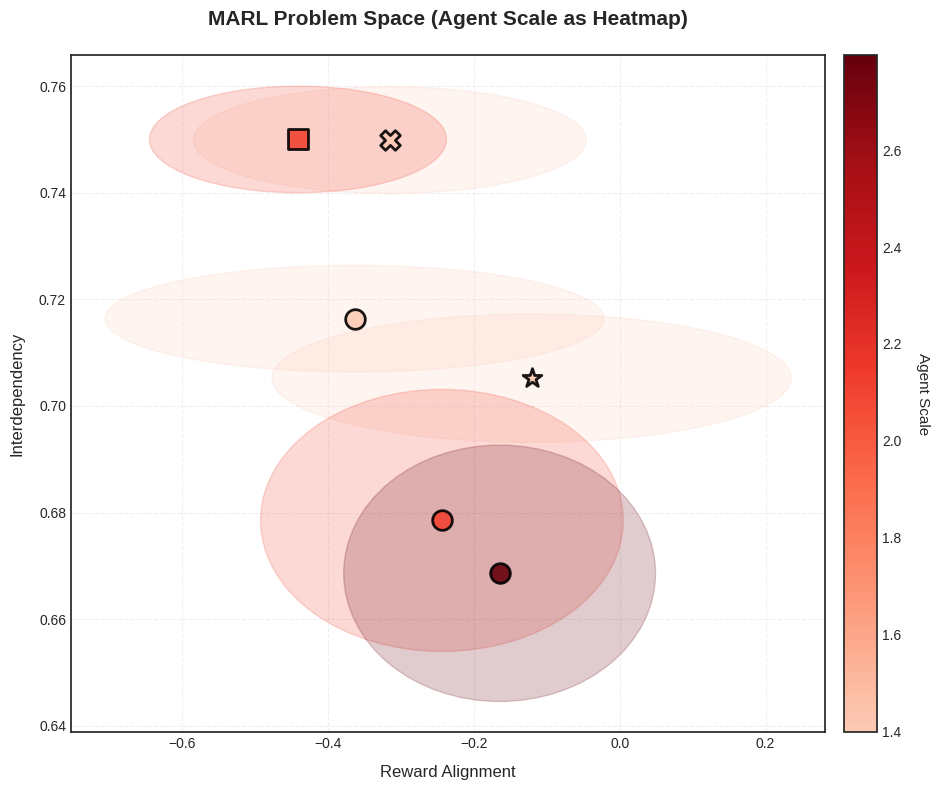

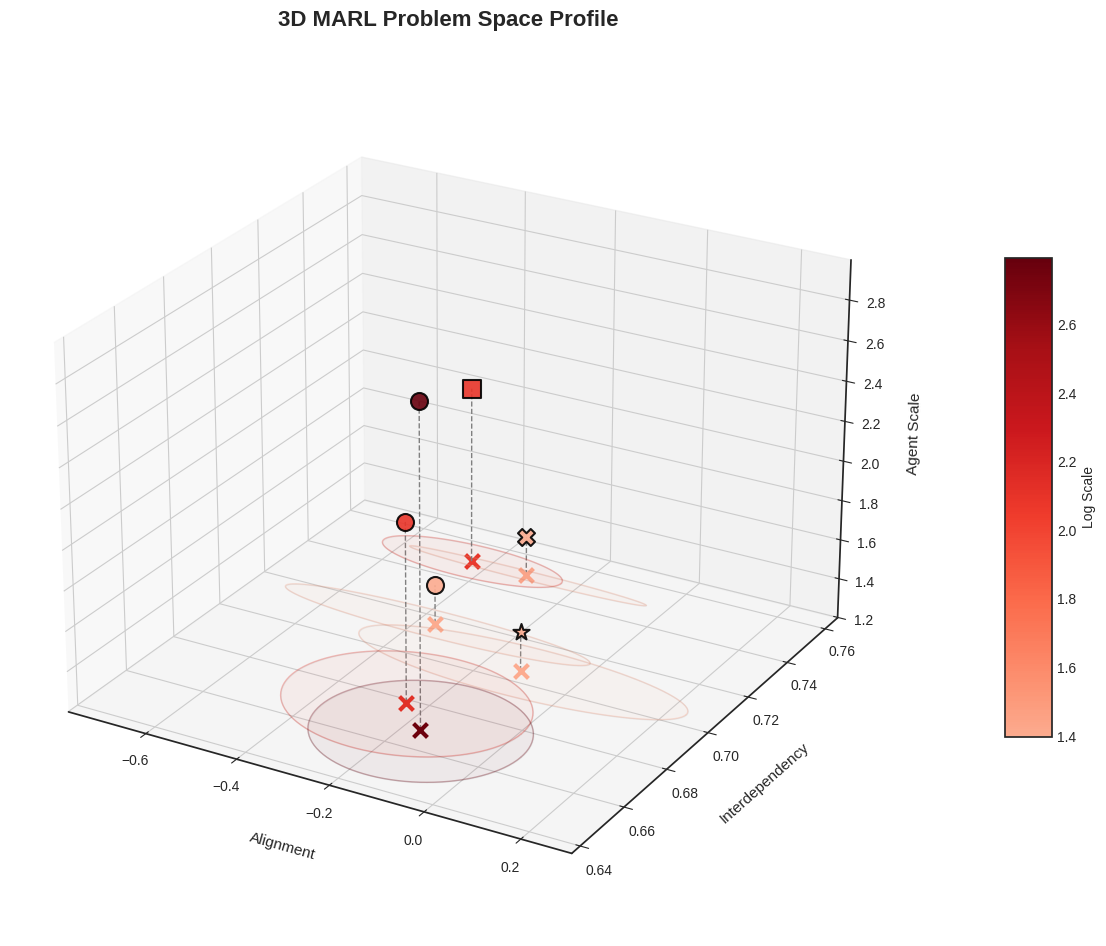

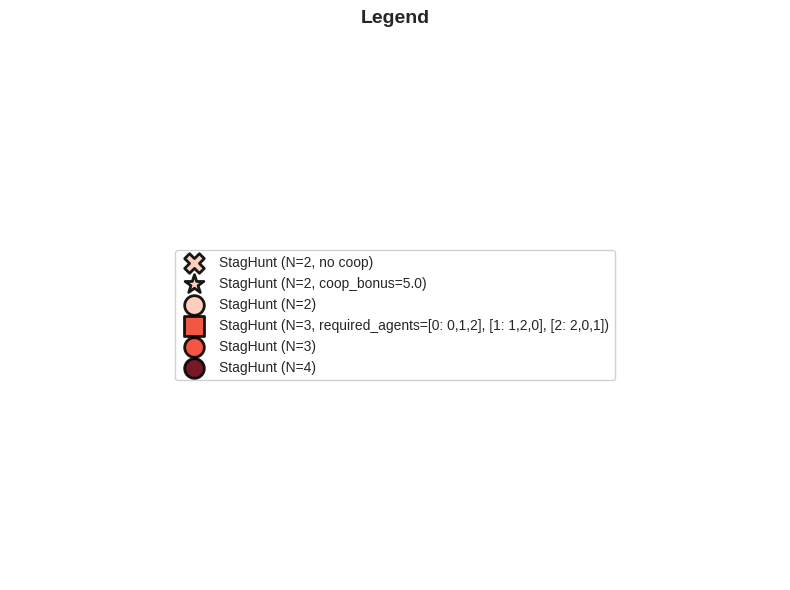

In [ ]:
marker_dict = {}
for config in env_configs:
    # marker 정보 저장
    marker_dict[config["name"]] = config.get("marker", "o")

profiler.plot_marl_space(all_results, marker_dict=marker_dict)
profiler.plot_marl_space_3D(all_results, marker_dict=marker_dict)  # marker_dict 전달

# 별도의 legend 생성 및 저장
profiler.plot_legend(all_results, marker_dict=marker_dict)